In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from ipywidgets import interact, IntSlider, Combobox, Dropdown, Checkbox
from tqdm import tqdm
from ast import literal_eval

In [27]:
data_dir = Path('../data/train')
sample_names = [f.stem for f in data_dir.glob('*.npz')]
len(sample_names)

1427

In [4]:
data = np.load('../data/train/0522c0001+9Ag+MOS_23629.npz', allow_pickle=True)['arr_0'].item()
data.keys()

dict_keys(['PTV_Total', 'ParotidCon-PTV', 'ParotidIps-PTV', 'Parotids', 'Parotids-PTV', 'PharConst-PTV', 'PharynxConst', 'PTV70', 'OralCavity', 'OpticNerve_R', 'OpticNerve_L', 'OCavity-PTV', 'Mandible-PTV', 'Mandible', 'Lungs', 'Lips', 'Lens_R', 'Lens_L', 'Larynx-PTV', 'Larynx', 'LacrimalGlands', 'Eyes', 'Cochlea_R', 'Cochlea_L', 'Chiasm', 'BrainStem_03', 'BrainStem', 'Brain', 'BrachialPlexus', 'Body', 'Pituitary', 'Posterior_Neck', 'Shoulders', 'SpinalCord', 'SpinalCord_05', 'Submand-PTV', 'SubmandL-PTV', 'SubmandR-PTV', 'Submandibular', 'Thyroid', 'Thyroid-PTV', 'all_mask', 'img', 'dose', 'dose_scale', 'isVMAT', 'isocenter', 'angle_list', 'origin', 'spacing', 'direction', 'size', 'angle_plate', 'beam_plate', 'PTVHighOPT', 'RingPTVHigh'])

In [37]:
for key in data.keys():
    print(key)

    if isinstance(data[key], np.ndarray):
        print(data[key].shape)
    else:
        print(data[key])
    print('-' * 100)

Body
(128, 141, 183)
----------------------------------------------------------------------------------------------------
BrachialPlexus
(128, 141, 183)
----------------------------------------------------------------------------------------------------
Brain
(128, 141, 183)
----------------------------------------------------------------------------------------------------
BrainStem
(128, 141, 183)
----------------------------------------------------------------------------------------------------
BrainStem_03
(128, 141, 183)
----------------------------------------------------------------------------------------------------
Chiasm
(128, 141, 183)
----------------------------------------------------------------------------------------------------
Cochlea_L
(128, 141, 183)
----------------------------------------------------------------------------------------------------
Cochlea_R
(128, 141, 183)
-----------------------------------------------------------------------------------------

In [ ]:
paramtools = {
    'sample_name': Combobox(value=sample_names[0], options=sample_names, ensure_option=True),
    'slice_idx': IntSlider(min=0, max=240, step=1)
}

@interact(**paramtools)
def show_interactive(sample_name, slice_idx):
    data = np.load(data_dir / f'{sample_name}.npz', allow_pickle=True)['arr_0'].item()

    print('Dimensions of CT:', data['img'].shape)
    print('Dimensions of Dose:', data['dose'].shape)

    fig, axes = plt.subplots(
        nrows=3,
        ncols=3,
        figsize=(20, 15)
    )

    if slice_idx < data['img'].shape[0]:
      axes[0][0].imshow(data['img'][slice_idx], cmap='gray')
    axes[0][0].axis('off')
    axes[0][0].set_title('View from Axial plane')

    if slice_idx < data['img'].shape[1]:
      axes[0][1].imshow(data['img'][::-1, slice_idx, :], cmap='gray')
    axes[0][1].axis('off')
    axes[0][1].set_title('View from Sagittal plane')

    if slice_idx < data['img'].shape[2]:
      axes[0][2].imshow(data['img'][::-1, ::-1, slice_idx], cmap='gray')
    axes[0][2].axis('off')
    axes[0][2].set_title('View from Coronal plane')

    if slice_idx < data['dose'].shape[0]:
      axes[1][0].imshow(data['dose'][slice_idx], cmap='jet')
    axes[1][0].axis('off')
    axes[1][0].set_title('View from Axial plane')

    if slice_idx < data['dose'].shape[1]:
      axes[1][1].imshow(data['dose'][::-1, slice_idx, :], cmap='jet')
    axes[1][1].axis('off')
    axes[1][1].set_title('View from Sagittal plane')

    if slice_idx < data['dose'].shape[2]:
      axes[1][2].imshow(data['dose'][::-1, ::-1, slice_idx], cmap='jet')
    axes[1][2].axis('off')
    axes[1][2].set_title('View from Coronal plane')

    if slice_idx < data['PTV_Total'].shape[0]:
      axes[2][0].imshow(data['PTV_Total'][slice_idx], cmap='gray')
    axes[2][0].axis('off')
    axes[2][0].set_title('View from Axial plane')

    if slice_idx < data['PTV_Total'].shape[1]:
      axes[2][1].imshow(data['PTV_Total'][::-1, slice_idx, :], cmap='gray')
    axes[2][1].axis('off')
    axes[2][1].set_title('View from Sagittal plane')

    if slice_idx < data['PTV_Total'].shape[2]:
      axes[2][2].imshow(data['PTV_Total'][::-1, ::-1, slice_idx], cmap='gray')
    axes[2][2].axis('off')
    axes[2][2].set_title('View from Coronal plane')

    fig.tight_layout()



interactive(children=(Combobox(value='HNC_189+9Ag+MOS_20547', description='sample_name', ensure_option=True, o…

In [ ]:
metadata = []

for sample_name in (pbar := tqdm(sample_names)):
  pbar.set_description(f'Processing {sample_name}')
  data = np.load(data_dir / f'{sample_name}.npz', allow_pickle=True)['arr_0'].item()

  metadata_entry = {
    'sample_name': sample_name
  }

  for key in data.keys():
    if isinstance(data[key], np.ndarray):
      metadata_entry[f'{key}_shape'] = data[key].shape
      metadata_entry[f'{key}_range'] = (data[key].min().item(), data[key].max().item())

      if np.any(data[key] > 0):
        coords = np.argwhere(data[key] > 0)
        min_coords = coords.min(axis=0)
        max_coords = coords.max(axis=0)
        bbox = max_coords - min_coords + 1

        metadata_entry[f'{key}_bbox'] = tuple(min_coords) + tuple(bbox)
      else:
        metadata_entry[f'{key}_bbox'] = np.nan
    else:
      metadata_entry[key] = data[key]

  metadata.append(metadata_entry)



Processing HNSCC-01-0054+A4Ac+MOS_0511:   0%|          | 2/1427 [00:00<09:51,  2.41it/s]

In [84]:
pd.DataFrame(metadata).set_index('sample_name').to_csv('../data/train_metadata.csv')

In [85]:
metadata = pd.read_csv('../data/train_metadata.csv')
for col in metadata.columns[metadata.columns.str.endswith(('_shape', '_range', '_bbox'))]:
  metadata[col] = metadata[col].apply(lambda x: literal_eval(x) if isinstance(x, str) else None)

metadata

SyntaxError: invalid syntax. Perhaps you forgot a comma? (<unknown>, line 1)

In [64]:
missings = metadata.isna().sum()
missings

sample_name              0
Trachea_shape          361
Trachea_range          361
Thyroid-PTV_shape       21
Thyroid-PTV_range       21
                      ... 
PTVLowOPT_range        103
PTVLow-PTVMid_shape    103
PTVLow-PTVMid_range    103
PTVLow_shape           103
PTVLow_range           103
Length: 125, dtype: int64

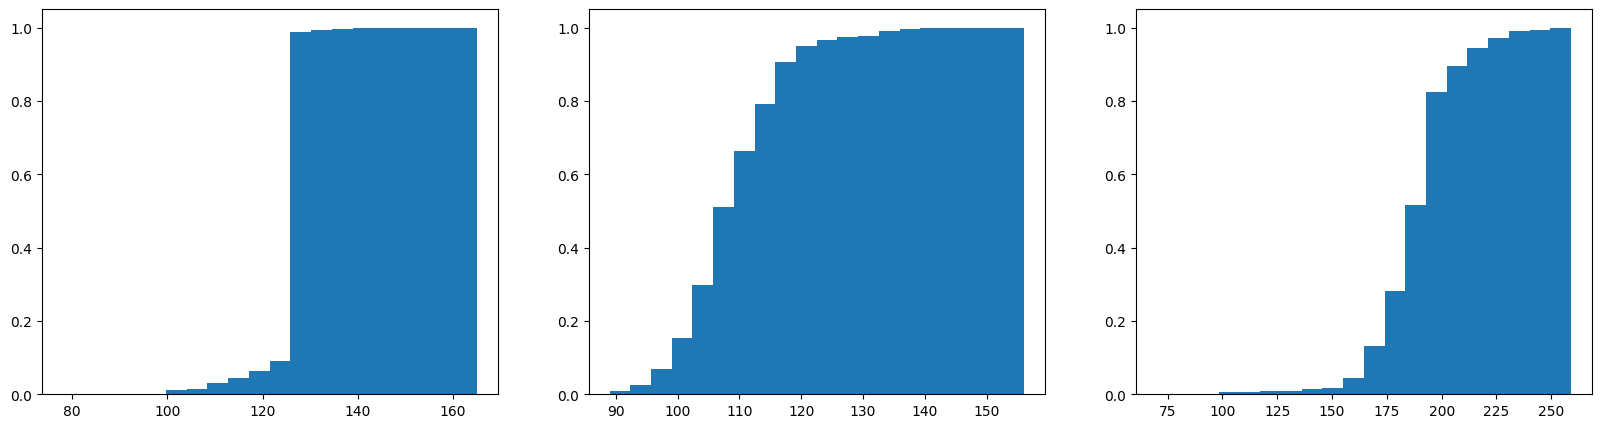

In [76]:
img_shapes = np.array(metadata['img_shape'].tolist())

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for i in range(3):
  axs[i].hist(img_shapes[:, i], cumulative=True, density=True, bins=20)

Deviating sizes:


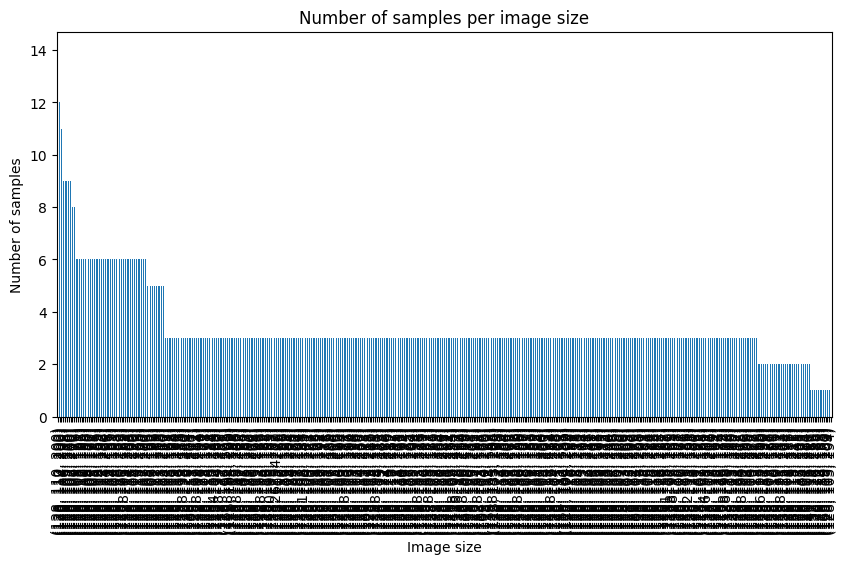

In [30]:
print('Deviating sizes:')
for sample_name in deviating_sizes:
    print(sample_name)

# print('Number of VMAT samples:', len(vmat_samples))

img_size_counts = pd.Series(img_sizes).value_counts()
fig, ax = plt.subplots(figsize=(10, 5))
img_size_counts.plot(kind='bar', ax=ax)
ax.set_title('Number of samples per image size')
ax.set_xlabel('Image size')
ax.set_ylabel('Number of samples')
plt.show()

In [35]:
np.array(img_sizes).min(axis=0), np.array(img_sizes).max(axis=0)

(array([78, 89, 70]), array([165, 156, 259]))